# What's New in Spring Framework 7 and Spring Boot 4

Spring Framework 7 and Spring Boot 4 bring major platform upgrades: Jakarta EE 11, JDK 25 alignment, a fully modularised autoconfigure layer, native API versioning, Jackson 3, OpenTelemetry out of the box, Hibernate 7, and Spring Security 7 with cleaner DSL defaults. This notebook covers all four modules of the course in a single reference document.

## Table of Contents

1. [Module 01: Platform Baselines and Core Configuration Changes](#module-01-platform-baselines-and-core-configuration-changes)
   - Jakarta EE 11, JDK alignment, virtual threads, JSpecify null safety, Spring Boot modularization, configuration property changes
2. [Module 02: Web Stack Evolution and Standardized Error Handling](#module-02-web-stack-evolution-and-standardized-error-handling)
   - Native API versioning, RestClient, Problem Details (RFC 9457), Jackson 3, web breaking changes
3. [Module 03: Observability, Data Layer Updates, and Application Packaging](#module-03-observability-data-layer-updates-and-application-packaging)
   - OpenTelemetry starter, Hibernate 7 / JPA 3.2, Spring Data 2025.1, AOT repositories, native image changes
4. [Module 04: Security Defaults, Testing Updates, and the Migration Plan](#module-04-security-defaults-testing-updates-and-the-migration-plan)
   - Spring Security 7, PathPatternRequestMatcher, simplified CSRF, MockitoBean, RestTestClient, migration checklist

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

## Module 01: Platform Baselines and Core Configuration Changes

Spring Boot 4 aligns with Jakarta EE 11, JDK 25, and a restructured autoconfigure layer. This module covers the key platform upgrades and the configuration/dependency changes you must make when migrating.

### Jakarta EE 11

Spring Boot 4 requires Jakarta EE 11 as its baseline, bringing three updated specifications and the full removal of `javax.*` packages.

| Specification | Version | Key Change |
|---|---|---|
| Servlet | 6.1 | HTTP handling changes; Security Manager removed |
| JPA | 3.2 | Now paired with Hibernate 7 |
| Bean Validation | 3.1 | Guaranteed annotation detection on records |
| Javax → Jakarta | — | All legacy `javax.*` packages removed |

#### Servlet 6.1

The Java Security Manager was deprecated since JDK 17 and is now removed entirely in Servlet 6.1. Not all containers support 6.1 yet — Undertow does not support it, so it is no longer an option.

**Alternatives to Undertow:**

```xml
<!-- Remove this -->
<dependency>
    <groupId>org.springframework.boot</groupId>
    <artifactId>spring-boot-starter-undertow</artifactId>
</dependency>
<!-- Or switch to Jetty: -->
<dependency>
    <groupId>org.springframework.boot</groupId>
    <artifactId>spring-boot-starter-jetty</artifactId>
</dependency>
<!-- Tomcat 11 is the default — no dependency needed -->
```

Supported embedded servers: **Apache Tomcat 11**, **Eclipse Jetty 12.1**, **Reactor Netty**.

#### Bean Validation 3.1

Constraint annotations on Java records were not always detected in earlier implementations. Bean Validation 3.1 guarantees consistent behaviour across all implementations.

```java
public record CreateUserRequest(
    @NotBlank String username,
    @Email String email,
    @Size(min = 8) String password
) {}
```

#### Javax to Jakarta Migration

Spring 7 removes all support for legacy `javax.*` packages — there is no compatibility shim.

```java
// These no longer compile — removed entirely
import javax.annotation.PostConstruct;
import javax.inject.Inject;

// Must use jakarta equivalents
import jakarta.annotation.PostConstruct;
import jakarta.inject.Inject;
```

### JDK Alignment

Spring Framework 7 requires JDK 17 as the minimum but targets JDK 25 LTS as the recommended version.

| Component | Minimum | Recommended |
|---|---|---|
| JDK | 17 | 25 (LTS) |
| Kotlin | 2.2 | 2.2+ |
| GraalVM | 25 | 25 |
| Gradle | 8.14 | 9.x |

#### Virtual Threads

Virtual threads (Project Loom) are available on JDK 21+ and are fully supported in Spring 7. They allow far more concurrent operations than platform threads without the complexity of reactive programming.

Enable with a single property:

```yaml
# application.yml
spring:
  threads:
    virtual:
      enabled: true
```

#### @ConcurrencyLimit

A new `@ConcurrencyLimit` annotation lets you cap the number of concurrent calls to a method — useful for protecting downstream services from being overwhelmed.

```java
@Configuration
@EnableResilientMethods
public class AppConfig {}

@Service
public class PaymentService {
    @ConcurrencyLimit(5)  // Max 5 concurrent calls
    public PaymentResult processPayment(Order order) {
        return paymentClient.charge(order);
    }
}
```

#### Class-File API

JDK 24 provides a standard Class-File API that replaces the internal ASM fork Spring previously bundled. No code changes are needed — Spring transparently switches to the JDK API.

#### JSpecify Null Safety

Spring 7 adopts JSpecify annotations for null safety, providing compile-time guarantees that were previously missing.

```java
// UserService.java
import org.jspecify.annotations.NullMarked;
import org.jspecify.annotations.Nullable;

@NullMarked
public class UserService {
    public @Nullable User findById(String id) {
        // May return null if user not found
        return userRepository.findById(id).orElse(null);
    }

    public User createUser(CreateUserRequest request) {
        // Never returns null; request cannot be null (implied by @NullMarked)
        return userRepository.save(new User(request));
    }
}
```

`@NullMarked` on a class declares that all parameters and return types are non-null by default; `@Nullable` marks exceptions. Kotlin respects these annotations, giving cleaner Java/Kotlin interoperability with fewer platform types.

### Spring Boot Modularization

The biggest structural change in Spring Boot 4: `spring-boot-autoconfigure` is no longer a monolithic JAR containing auto-configuration for every technology. Each technology area is now a separate module with its own autoconfigure code.


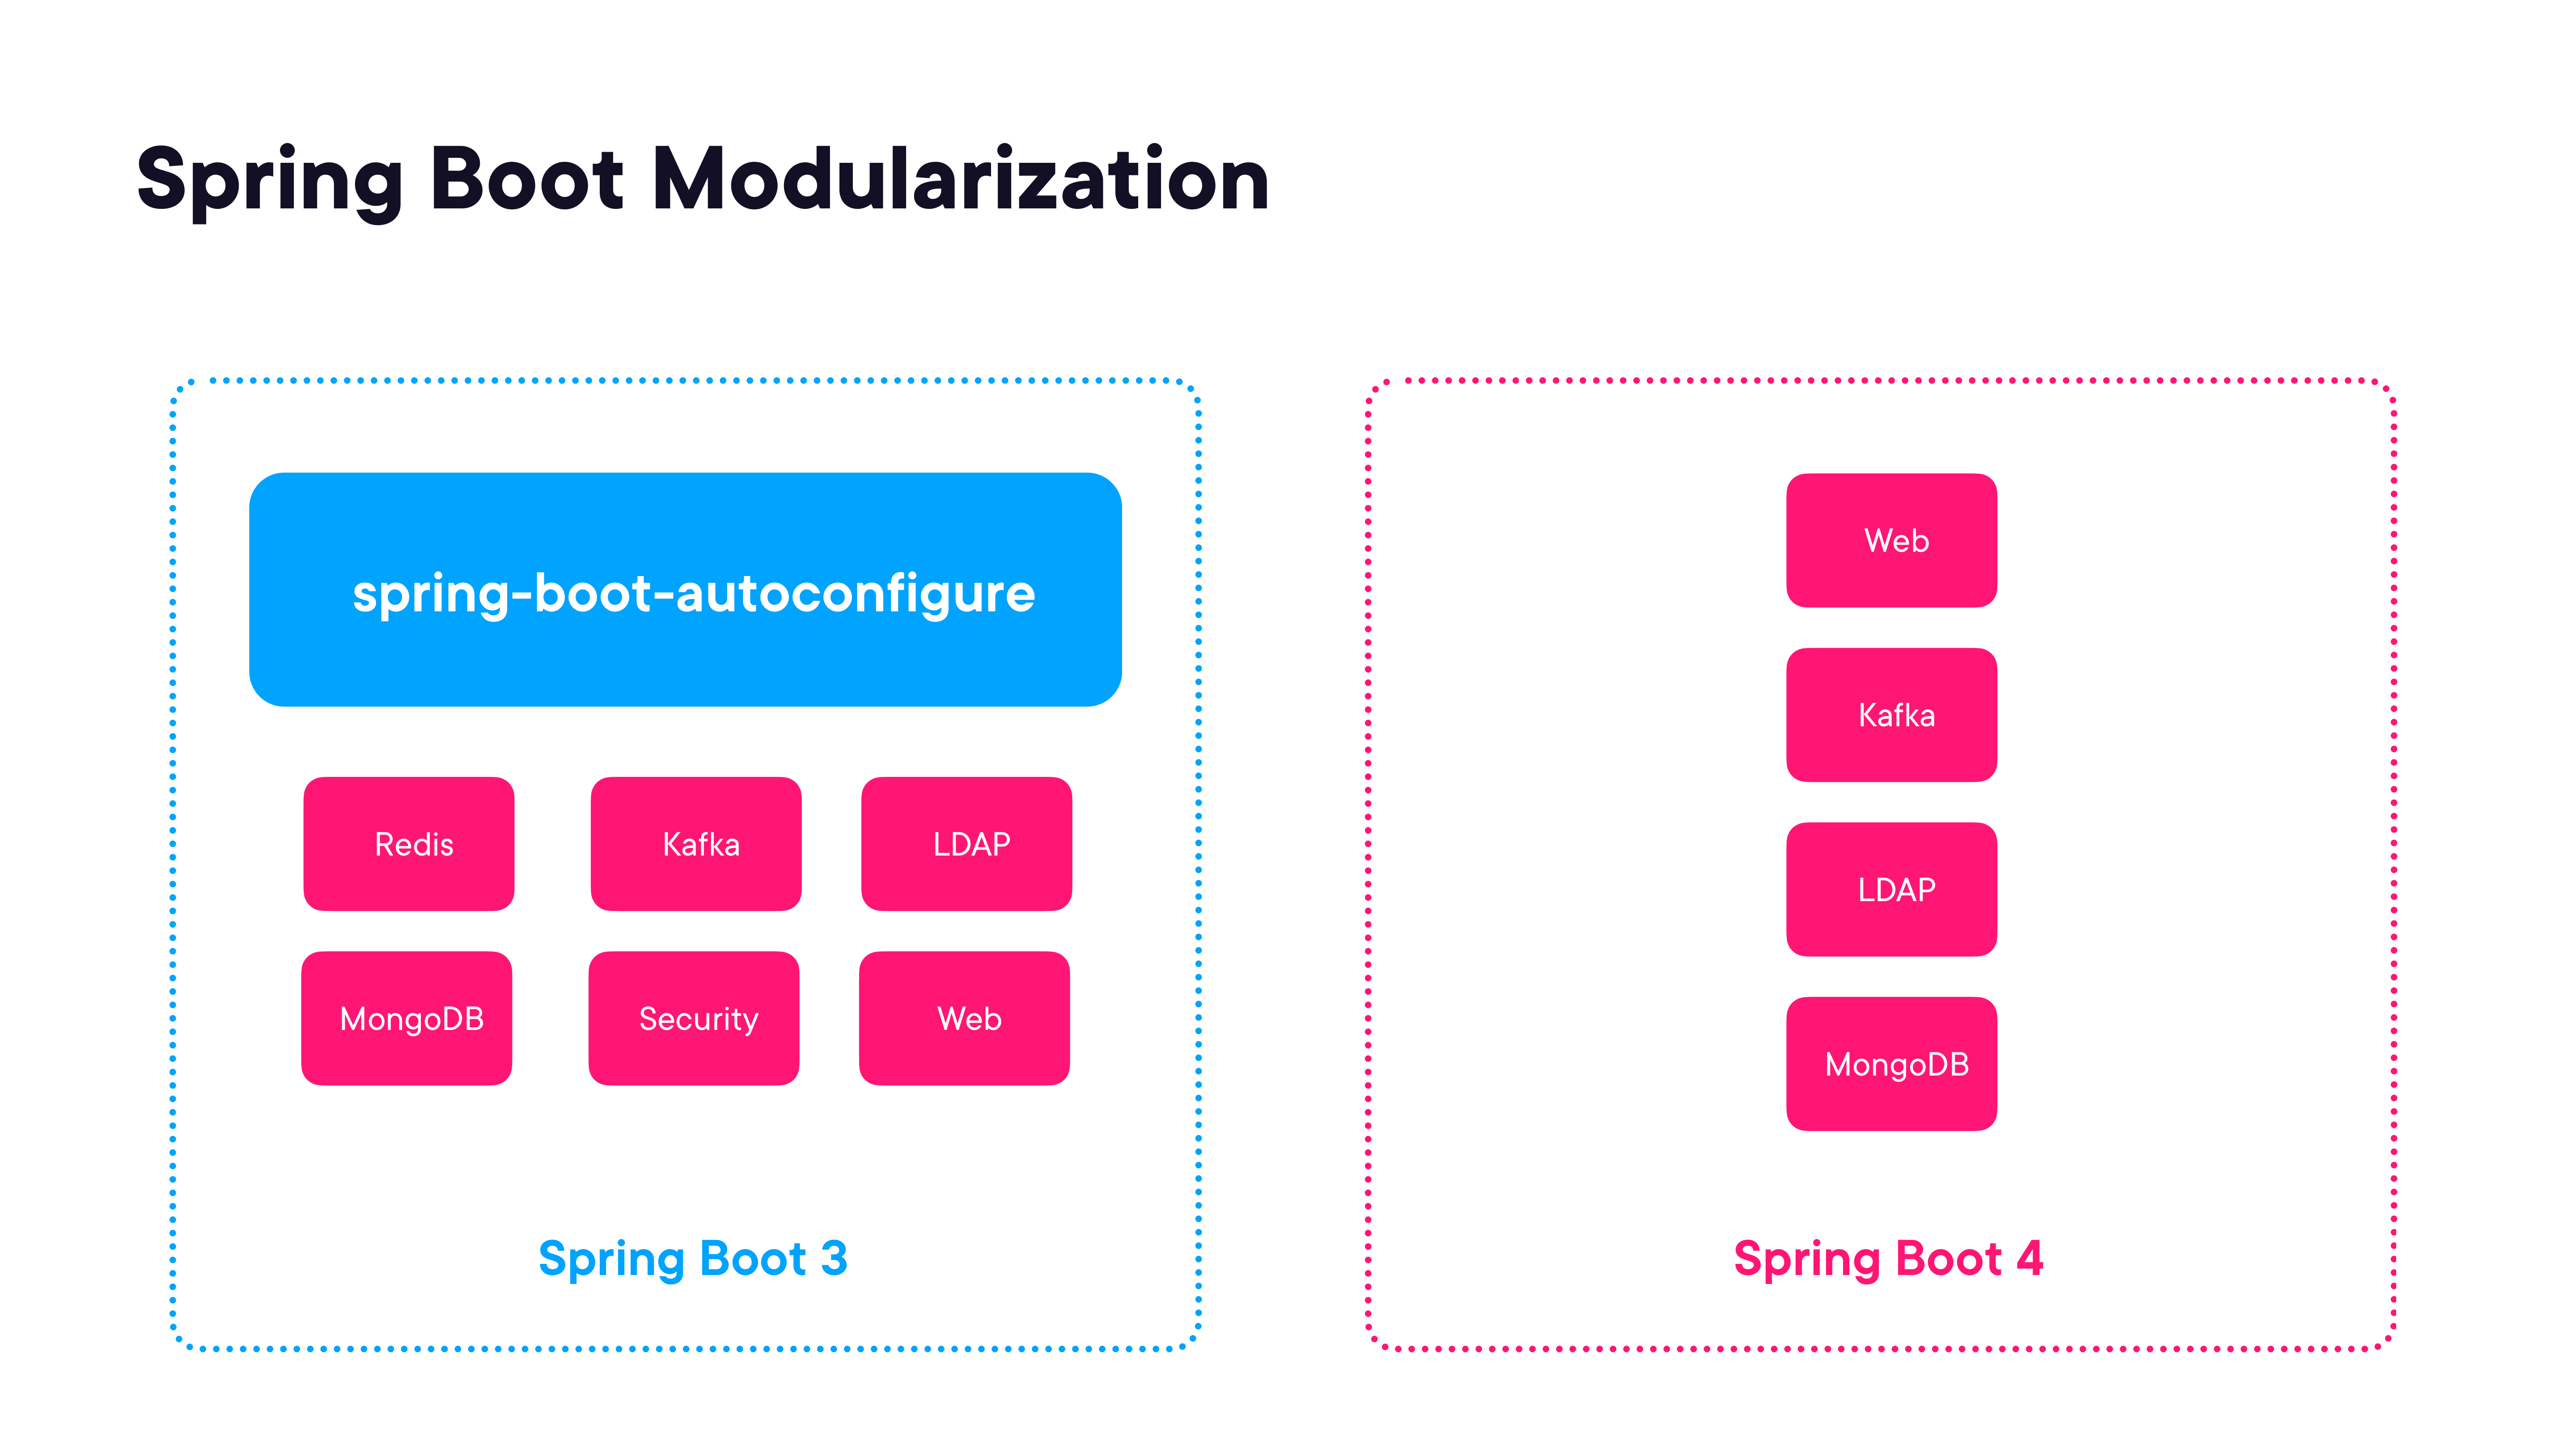

In [2]:
render_diagram(Path("assets/01-spring-boot-modularization.png"))

**Spring Boot 3:** a single `spring-boot-autoconfigure` JAR bundled auto-configuration for Redis, Kafka, LDAP, MongoDB, Security, Web, and everything else. Add any library and it would be auto-configured automatically.

**Spring Boot 4:** each technology ships its own dedicated module (`spring-boot-webmvc`, `spring-boot-security`, `spring-boot-data-jpa`, etc.). You must declare the matching starter explicitly.

#### Impact on Builds

In Spring Boot 3, adding `flyway-core` was enough — the monolithic autoconfigure JAR detected it automatically. In Spring Boot 4 you must add the dedicated starter:

```xml
<!-- Spring Boot 3.x — this was enough -->
<dependency>
    <groupId>org.flywaydb</groupId>
    <artifactId>flyway-core</artifactId>
</dependency>

<!-- Spring Boot 4.x — you need the starter -->
<dependency>
    <groupId>org.springframework.boot</groupId>
    <artifactId>spring-boot-starter-flyway</artifactId>
</dependency>
```

Same pattern applies to Liquibase (`spring-boot-starter-liquibase`) and Quartz (`spring-boot-starter-quartz`).

#### Starter Renames

Several starters were renamed to reflect the new module structure:

| Old Name | New Name |
|---|---|
| `spring-boot-starter-web` | `spring-boot-starter-webmvc` |
| `spring-boot-starter-oauth2-authorization-server` | `spring-boot-starter-security-oauth2-authorization-server` |
| `spring-boot-starter-oauth2-client` | `spring-boot-starter-security-oauth2-client` |
| `spring-boot-starter-oauth2-resource-server` | `spring-boot-starter-security-oauth2-resource-server` |
| `spring-boot-starter-web-services` | `spring-boot-starter-webservices` |

```xml
<!-- Spring Boot 3.x (still compiles in 4.x but deprecated) -->
<dependency>
    <groupId>org.springframework.boot</groupId>
    <artifactId>spring-boot-starter-web</artifactId>
</dependency>

<!-- Spring Boot 4.x — the recommended name -->
<dependency>
    <groupId>org.springframework.boot</groupId>
    <artifactId>spring-boot-starter-webmvc</artifactId>
</dependency>
```

Each starter now also has a matching **test starter**: e.g. `spring-boot-starter-webmvc-test`. For a quick start that retains the old behaviour, use `spring-boot-starter-classic`.

### Configuration and Dependency Changes

#### Spring Boot Properties Migrator

Add this dependency temporarily during migration. It logs warnings for deprecated properties and shows the exact replacements — remove it before production.

```xml
<dependency>
    <groupId>org.springframework.boot</groupId>
    <artifactId>spring-boot-properties-migrator</artifactId>
    <scope>runtime</scope>
</dependency>
```

#### Changed Property Keys

Several property namespaces moved in Spring Boot 4:

**MongoDB:**
```properties
# Spring Boot 3.x
spring.data.mongodb.uri=mongodb://localhost/mydb
spring.data.mongodb.database=mydb

# Spring Boot 4.x
spring.mongodb.uri=mongodb://localhost/mydb
spring.mongodb.database=mydb
```

**Jackson:**
```properties
# Spring Boot 3.x (Jackson 2)
spring.jackson.deserialization.fail-on-unknown-properties=false
spring.jackson.serialization.write-dates-as-timestamps=false

# Spring Boot 4.x (Jackson 3)
spring.jackson.json.read.fail-on-unknown-properties=false
spring.jackson.json.write.write-dates-as-timestamps=false
```

**Session:**
```properties
# Spring Boot 3.x
spring.session.redis.namespace=spring:session

# Spring Boot 4.x
spring.session.data.redis.namespace=spring:session
```

#### @ConfigurationProperties Binding Change

Spring Boot 4 removes support for binding configuration properties directly to public fields. You must use getters and setters.

```java
// This no longer works in Spring Boot 4
@ConfigurationProperties("app")
public class AppProperties {
    public String name;  // Public field binding removed
}

// You need getters and setters
@ConfigurationProperties("app")
public class AppProperties {
    private String name;

    public String getName() { return name; }
    public void setName(String name) { this.name = name; }
}
```

#### Module and API Removals

Spring Boot 4 removes several deprecated modules and APIs:

- `spring-jcl` removed — remove any explicit exclusions referencing it
- `webjars-locator-core` → replace with `webjars-locator-lite`
- `ListenableFuture` → replace with `CompletableFuture`
- OkHttp3 support removed
- MVC theme support removed

**JPA 3.2 — EntityManager Injection:**
```java
// Spring Boot 3.x / JPA 3.1 — @PersistenceContext was required
@PersistenceContext
private EntityManager entityManager;

// Spring Boot 4.x / JPA 3.2 — @Autowired also works now
@Autowired
private EntityManager entityManager;
```

**Hibernate 7 — Stricter Query Validation:**
```java
// Hibernate 6 — no result type required
List results = session.createQuery("from Order").getResultList();

// Hibernate 7 — must specify result type explicitly
List<Order> results = session.createQuery("from Order", Order.class).getResultList();
```

Queries that were previously accepted as ambiguous are now rejected at startup.

## Module 02: Web Stack Evolution and Standardized Error Handling

Spring Framework 7 adds native API versioning, deprecates `RestTemplate` in favour of `RestClient`, standardises error responses using RFC 9457 Problem Details, and introduces breaking changes in Jackson 3 and HTTP path matching.

### API Versioning

Before Spring 7, API versioning required custom annotations or separate controller classes per version. Spring Framework 7 adds native versioning built directly into `@RequestMapping`.

#### Before: Separate Controllers per Version (Spring 6.x)

```java
@RestController
@RequestMapping("/api/v1/products")
public class ProductControllerV1 {
    @GetMapping("/{id}")
    public ProductV1 getProduct(@PathVariable Long id) { ... }
}

@RestController
@RequestMapping("/api/v2/products")
public class ProductControllerV2 {
    @GetMapping("/{id}")
    public ProductV2 getProduct(@PathVariable Long id) { ... }
}
```

#### After: Single Controller with `version` Attribute (Spring 7)

```java
@RestController
@RequestMapping("/api/products")
public class ProductController {
    @GetMapping("/{id}", version = "1")
    public ProductV1 getProductV1(@PathVariable Long id) { ... }

    @GetMapping("/{id}", version = "2")
    public ProductV2 getProductV2(@PathVariable Long id) { ... }
}
```

#### Version Matching Modes

Three modes are supported on the `version` attribute:

| Syntax | Mode | Behaviour |
|---|---|---|
| `@GetMapping(version = "1.5")` | Fixed | Matches exactly version 1.5 |
| `@GetMapping(version = "1.2+")` | Baseline | Matches 1.2 and anything above |
| `@GetMapping` | Fallback | Matches any request with no specific handler |

**Full example with multiple versions on one controller:**

```java
// AccountController.java
@RestController
@RequestMapping("/accounts/{id}")
public class AccountController {
    @GetMapping                      // Fallback for any version
    public Account getAccount() { ... }

    @GetMapping(version = "1.1")    // Exact match for 1.1
    public Account getAccountV1_1() { ... }

    @GetMapping(version = "1.2+")   // Match 1.2 and above
    public Account getAccountV1_2() { ... }

    @GetMapping(version = "1.5")    // Exact match for 1.5
    public Account getAccountV1_5() { ... }
}
```

#### Versioning Strategies

| Strategy | Client Request Example |
|---|---|
| Request Header | `API-Version: 2` |
| Path Segment | `/api/v2/products` |
| Query Parameter | `/products?api-version=2` |
| Media Type | `Accept: application/json;version=2` |

**YAML configuration:**

```yaml
# Header-based
spring:
  mvc:
    apiversion:
      use:
        header: API-Version

# Path-segment-based (0-indexed position)
spring:
  mvc:
    apiversion:
      use:
        path-segment: 1
```

**Java configuration:**

```java
// WebConfig.java
@Configuration
public class WebConfig implements WebMvcConfigurer {
    @Override
    public void configureApiVersioning(ApiVersionConfigurer configurer) {
        configurer.useRequestHeader("API-Version");
        // Or: configurer.usePathSegment(1);
        // Or: configurer.useQueryParam("api-version");
        // Or: configurer.useMediaTypeParameter(MediaType.APPLICATION_JSON, "version");
        configurer.addSupportedVersions("1.3", "1.4");
    }
}
```

#### Client-Side Versioning with RestClient

```java
RestClient client = RestClient.builder()
    .baseUrl("http://localhost:8080")
    .apiVersionInserter(ApiVersionInserter.useHeader("API-Version"))
    .build();

Account account = client.get()
    .uri("/accounts/1")
    .apiVersion("1.2")
    .retrieve()
    .body(Account.class);
```

#### Deprecation Headers

Spring automatically adds RFC-standard deprecation headers to responses for deprecated versions:

```java
StandardApiVersionDeprecationHandler handler = new StandardApiVersionDeprecationHandler();
handler.configureVersion("1")
    .setDeprecationDate(ZonedDateTime.parse("2025-06-01T00:00:00Z"))
    .setSunsetDate(ZonedDateTime.parse("2026-01-01T00:00:00Z"))
    .setDeprecationLink(URI.create("https://api.example.com/docs/v2-migration"));
configurer.setDeprecationHandler(handler);
```

The response automatically includes:
```http
HTTP/1.1 200 OK
Deprecation: Sun, 01 Jun 2025 00:00:00 GMT
Sunset: Thu, 01 Jan 2026 00:00:00 GMT
Link: <https://api.example.com/docs/v2-migration>; rel="deprecation"; type="text/html"
```

### RestClient — Replacing RestTemplate

`RestTemplate` is being deprecated in favour of `RestClient`, which was introduced in Spring 6.1. It provides a modern fluent API for synchronous HTTP calls.

**RestTemplate deprecation timeline:**

| Version | Status |
|---|---|
| Spring 7.0 (Nov 2025) | Deprecated in documentation |
| Spring 7.1 (Nov 2026) | `@Deprecated` annotation applied |
| Spring 8.0 | Expected removal |

#### Side-by-Side Comparison

**RestTemplate (old):**
```java
RestTemplate restTemplate = new RestTemplate();

// GET
User user = restTemplate.getForObject(
    "http://localhost:8080/users/{id}", User.class, 42);

// POST
User created = restTemplate.postForObject(
    "http://localhost:8080/users", newUser, User.class);

// POST with custom headers — requires wrapping in HttpEntity
HttpHeaders headers = new HttpHeaders();
headers.setBearerAuth(token);
HttpEntity<User> entity = new HttpEntity<>(newUser, headers);
ResponseEntity<User> response = restTemplate.exchange(
    "http://localhost:8080/users", HttpMethod.POST, entity, User.class);
```

**RestClient (new):**
```java
RestClient restClient = RestClient.builder()
    .baseUrl("http://localhost:8080")
    .build();

// GET — fluent pattern
User user = restClient.get()
    .uri("/users/{id}", 42)
    .retrieve()
    .body(User.class);

// POST — fluent pattern
User created = restClient.post()
    .uri("/users")
    .body(newUser)
    .retrieve()
    .body(User.class);

// POST with custom headers — just add .header() to the chain
User createdWithAuth = restClient.post()
    .uri("/users")
    .header(HttpHeaders.AUTHORIZATION, "Bearer " + token)
    .body(newUser)
    .retrieve()
    .body(User.class);
```

#### Error Handling

```java
User user = restClient.get()
    .uri("/users/{id}", userId)
    .retrieve()
    .onStatus(HttpStatusCode::is4xxClientError, (request, response) -> {
        throw new UserNotFoundException("User not found: " + userId);
    })
    .onStatus(HttpStatusCode::is5xxServerError, (request, response) -> {
        throw new ServiceUnavailableException("User service unavailable");
    })
    .body(User.class);
```

#### Migrating Existing RestTemplate Code

If you have a `RestTemplate` with custom interceptors or error handlers, wrap it in a `RestClient` bridge rather than rewriting everything at once:

```java
// UserClient.java
RestTemplate existingRestTemplate = new RestTemplate();
existingRestTemplate.setInterceptors(List.of(loggingInterceptor));
existingRestTemplate.setErrorHandler(customErrorHandler);

// Wrap it — backed by your RestTemplate, uses the fluent API
RestClient restClient = RestClient.create(existingRestTemplate);

User user = restClient.get()
    .uri("/users/{id}", 42)
    .retrieve()
    .body(User.class);
```

### Problem Details (RFC 9457)

Spring Boot 4 standardises error responses using RFC 9457 Problem Details. Enable it with one property.

```yaml
# MVC
spring:
  mvc:
    problemdetails:
      enabled: true

# WebFlux
spring:
  webflux:
    problemdetails:
      enabled: true
```

#### Problem Details Response Fields

| Field | Purpose |
|---|---|
| `type` | A URI identifying the error type |
| `title` | A short, human-readable summary |
| `status` | The HTTP status code |
| `detail` | A human-readable explanation |
| `instance` | A URI identifying this specific occurrence |

#### Migration Impact — Old vs New Error Format

**Legacy error response (Spring Boot 3.x default):**
```json
{
  "timestamp": "2025-11-20T10:30:00Z",
  "status": 404,
  "error": "Not Found",
  "message": "No user with id: 42",
  "path": "/users/42"
}
```

**Problem Details format (Spring Boot 4 default):**
```json
{
  "type": "about:blank",
  "title": "Not Found",
  "status": 404,
  "detail": "No user with id: 42",
  "instance": "/users/42"
}
```

> The field names change (`message` → `detail`, `path` → `instance`, `error` → `title`). Any API clients that parse the error body by field name need updating.

#### Basic Usage — ResponseStatusException

With Problem Details enabled, throwing `ResponseStatusException` automatically produces a Problem Details response:

```java
@GetMapping("/users/{id}")
public User getUser(@PathVariable Long id) {
    return userRepository.findById(id)
        .orElseThrow(() -> new ResponseStatusException(
            HttpStatus.NOT_FOUND,
            "User not found with id: " + id
        ));
}
```

Response:
```http
HTTP/1.1 404 Not Found
Content-Type: application/problem+json

{
    "type": "about:blank",
    "title": "Not Found",
    "status": 404,
    "detail": "User not found with id: 42",
    "instance": "/users/42"
}
```

#### Custom Problem Details

```java
@RestControllerAdvice
public class GlobalExceptionHandler extends ResponseEntityExceptionHandler {
    @ExceptionHandler(UserNotFoundException.class)
    public ProblemDetail handleUserNotFound(UserNotFoundException ex,
                                             HttpServletRequest request) {
        ProblemDetail problem = ProblemDetail.forStatusAndDetail(
            HttpStatus.NOT_FOUND, ex.getMessage()
        );
        problem.setType(URI.create("https://api.example.com/errors/user-not-found"));
        problem.setTitle("User Not Found");
        problem.setInstance(URI.create(request.getRequestURI()));
        return problem;
    }
}
```

#### Adding Extension Fields

```java
ProblemDetail problem = ProblemDetail.forStatusAndDetail(
    HttpStatus.BAD_REQUEST, "Validation failed"
);
problem.setTitle("Validation Error");
problem.setProperty("timestamp", Instant.now());
problem.setProperty("requestId", "abc-123");
```

Response:
```http
HTTP/1.1 400 Bad Request
Content-Type: application/problem+json

{
    "title": "Validation Error",
    "status": 400,
    "detail": "Validation failed",
    "timestamp": "2025-11-20T10:30:00Z",
    "requestId": "abc-123"
}
```

### Jackson 3 — Breaking Changes

Spring Boot 4 ships with Jackson 3. Jackson 3 changes the package name, the main mapper class, default property ordering, and default date serialization.

#### Jackson 2 vs Jackson 3

| Aspect | Jackson 2.x | Jackson 3.x |
|---|---|---|
| Package | `com.fasterxml.jackson` | `tools.jackson` |
| Main class | `ObjectMapper` | `JsonMapper` |
| Property sorting | Declaration order | Alphabetical |
| Date serialization | Timestamps (epoch) | ISO-8601 strings |

#### Import Changes

```java
// Jackson 2.x
import com.fasterxml.jackson.databind.ObjectMapper;
import com.fasterxml.jackson.databind.SerializationFeature;
import com.fasterxml.jackson.annotation.JsonProperty;

// Jackson 3.x
import tools.jackson.databind.json.JsonMapper;       // new package
import tools.jackson.databind.SerializationFeature;  // new package
import com.fasterxml.jackson.annotation.JsonProperty; // annotations module unchanged
```

#### ObjectMapper vs JsonMapper

```java
// Jackson 2.x
ObjectMapper mapper = new ObjectMapper();
mapper.enable(SerializationFeature.INDENT_OUTPUT);

// Jackson 3.x — builder pattern, immutable after build
JsonMapper mapper = JsonMapper.builder()
    .enable(SerializationFeature.INDENT_OUTPUT)
    .build();
```

#### Serialization Output Differences

Given this class:
```java
public class User {
    private String name;
    private String email;
    private Instant createdAt;
    // getters and setters
}
```

**Jackson 2 output** (declaration order, epoch timestamp):
```json
{
  "name": "Jane",
  "email": "jane@example.com",
  "createdAt": 1731578400.000000000
}
```

**Jackson 3 output** (alphabetical order, ISO-8601):
```json
{
  "createdAt": "2024-11-14T10:00:00Z",
  "email": "jane@example.com",
  "name": "Jane"
}
```

> Any code that relies on field order or parses dates as epoch numbers will break.

#### Restoring Jackson 2 Behaviour (Temporary)

```yaml
# Restore both behaviours at once
spring:
  jackson:
    use-jackson2-defaults: true

# Or configure individually
spring:
  jackson:
    datatype:
      datetime:
        write-dates-as-timestamps: true
    mapper:
      sort-properties-alphabetically: false
```

#### Jackson 2 Bridge

For a longer transition, add the bridge dependency:

```xml
<dependency>
    <groupId>org.springframework.boot</groupId>
    <artifactId>spring-boot-jackson2</artifactId>
</dependency>
```

```yaml
spring:
  http:
    converters:
      preferred-json-mapper: jackson2
```

> The bridge is deprecated and temporary. Plan to migrate to Jackson 3. Also rename `@JsonComponent` → `@JacksonComponent` and `@JsonMixin` → `@JacksonMixin`.

### Web Stack Breaking Changes

#### HttpHeaders API Change

```java
// Spring 6.x — HttpHeaders implemented MultiValueMap
HttpHeaders headers = new HttpHeaders();
headers.put("X-Custom", Arrays.asList("value1", "value2"));
Map<String, List<String>> map = headers;  // Direct assignment worked

// Spring 7 — use HttpHeaders methods directly
HttpHeaders headers = new HttpHeaders();
headers.add("X-Custom", "value1");
headers.add("X-Custom", "value2");
List<String> values = headers.getValuesAsList("X-Custom");
// Temporary bridge if needed:
MultiValueMap<String, String> map = headers.asMultiValueMap();
```

#### Path Matching Removals

| Option | Status | What it Did | Migration |
|---|---|---|---|
| `suffixPatternMatch` | Removed | Matched `/users` and `/users.json` to same handler | Use `Accept` header instead |
| `favorPathExtension` | Removed | Content negotiation via URL extensions (`.json`, `.xml`) | Use `Accept` header instead |
| `trailingSlashMatch` | Removed | Matched `/users` and `/users/` to same handler | Add `@GetMapping({"/users", "/users/"})` |
| `AntPathMatcher` | Deprecated | Legacy path matching engine | Use `PathPattern` — now the only recommended option |

## Module 03: Observability, Data Layer Updates, and Application Packaging

Spring Boot 4 ships a single OpenTelemetry starter that replaces three separate dependencies, Hibernate upgrades to version 7 with stricter validation, Spring Data introduces AOT repositories, and native image packaging is simplified.

### OpenTelemetry in Spring Boot 4

#### Before and After — Dependencies

**Spring Boot 3.x** required three separate dependencies:

```xml
<dependencies>
    <dependency>
        <groupId>org.springframework.boot</groupId>
        <artifactId>spring-boot-starter-actuator</artifactId>
    </dependency>
    <dependency>
        <groupId>io.micrometer</groupId>
        <artifactId>micrometer-tracing-bridge-otel</artifactId>
    </dependency>
    <dependency>
        <groupId>io.opentelemetry</groupId>
        <artifactId>opentelemetry-exporter-otlp</artifactId>
    </dependency>
</dependencies>
```

**Spring Boot 4.x** — one starter handles all wiring:

```xml
<dependency>
    <groupId>org.springframework.boot</groupId>
    <artifactId>spring-boot-starter-opentelemetry</artifactId>
</dependency>
```

The starter bundles: OpenTelemetry API and SDK, pre-configured Micrometer tracing bridge, OTLP exporters for metrics and traces, and zero-code HTTP instrumentation.

#### What You Get Out of the Box

- **HTTP server instrumentation** — incoming requests traced automatically
- **HTTP client instrumentation** — outgoing calls traced across services
- **Log correlation** — trace IDs injected into log entries

#### Development Configuration

```yaml
# application.yml
management:
  tracing:
    sampling:
      probability: 1.0  # Sample 100% of requests in development
  otlp:
    metrics:
      export:
        url: http://localhost:4318/v1/metrics
  opentelemetry:
    tracing:
      export:
        otlp:
          endpoint: http://localhost:4318/v1/traces
```

#### Production Configuration

```yaml
management:
  tracing:
    sampling:
      probability: 0.1  # Sample 10% in production
  opentelemetry:
    resource-attributes:
      service.name: ${spring.application.name}
      deployment.environment: production
    tracing:
      export:
        otlp:
          endpoint: ${OTEL_COLLECTOR_ENDPOINT}
    logging:
      export:
        otlp:
          endpoint: ${OTEL_COLLECTOR_ENDPOINT}
```

#### Observability Test Changes

`@AutoConfigureObservability` is removed in Spring Boot 4 — replace it with separate annotations:

```java
// Spring Boot 3.x — single annotation
@SpringBootTest
@AutoConfigureObservability  // No longer exists in Boot 4
class MyObservabilityTest { ... }

// Spring Boot 4.x — use specific annotations
@SpringBootTest
@AutoConfigureMetrics   // For metrics
@AutoConfigureTracing   // For tracing
class MyObservabilityTest { ... }
```

### Hibernate 7 and JPA 3.2

Spring Boot 4 bundles Hibernate 7.2 and JPA 3.2.

| Spring Boot | Hibernate ORM | JPA |
|---|---|---|
| 3.0.x | 6.1 | 3.1 |
| 3.2.x+ | 6.x | 3.1 |
| 4.0 | **7.2** | **3.2** |

**Hibernate Validator** also upgrades to 9.x (implements Jakarta Validation 3.1). Existing annotations still work — the upgrade is seamless for most apps.

#### Simplified EntityManager Injection

```java
// Spring Boot 3.x — @PersistenceContext was required
@Repository
public class ProductRepository {
    @PersistenceContext
    private EntityManager entityManager;

    public Product findById(Long id) {
        return entityManager.find(Product.class, id);
    }
}

// Spring Boot 4.x — standard constructor injection works
@Repository
public class ProductRepository {
    private final EntityManager entityManager;

    public ProductRepository(EntityManager entityManager) {
        this.entityManager = entityManager;
    }

    public Product findById(Long id) {
        return entityManager.find(Product.class, id);
    }
}
```

Java Records can also be used as `@Embeddable` types and query targets.

#### Hibernate Package Migration

```java
// Spring Boot 3.x — hibernate5 package
import org.springframework.orm.hibernate5.LocalSessionFactoryBean;
import org.springframework.orm.hibernate5.HibernateTransactionManager;

// Spring Boot 4.x — moved to jpa.hibernate
import org.springframework.orm.jpa.hibernate.LocalSessionFactoryBean;
import org.springframework.orm.jpa.hibernate.HibernateTransactionManager;
```

#### Java-Based Persistence Configuration

JPA 3.2 makes `persistence.xml` optional. You can now configure the persistence unit entirely in Java:

```java
@Configuration
public class PersistenceConfig {
    @Bean
    public LocalContainerEntityManagerFactoryBean entityManagerFactory(DataSource dataSource) {
        LocalContainerEntityManagerFactoryBean factory =
            new LocalContainerEntityManagerFactoryBean();
        factory.setDataSource(dataSource);
        factory.setPackagesToScan("com.example.domain");

        PersistenceConfiguration config = new PersistenceConfiguration("myPU");
        config.property("hibernate.hbm2ddl.auto", "validate");
        config.property("hibernate.show_sql", "true");
        factory.setPersistenceConfiguration(config);
        return factory;
    }
}
```

#### Hibernate Upgrade Checklist

- Update `hibernate5` imports to `jpa.hibernate`
- Simplify `EntityManager` injection — remove `@PersistenceContext`, use constructor injection
- Review HQL/JPQL queries — stricter validation rejects previously ambiguous queries
- Test for Hibernate behaviour edge cases (e.g. lazy-loading, query result types)

#### Other Data Layer Changes

- **Spring Data JPA** — transition is largely transparent; backed by Hibernate 7 and Jakarta Persistence 3.2
- **R2DBC** — drivers updated, API unchanged
- **JDBC Support** — no significant changes

### Spring Data 2025.1 — AOT Repositories and Value Expressions

Spring Data 2025.1 ships with Spring Boot 4, adding AOT (Ahead-of-Time) repository generation and value expressions in annotations.

#### AOT Repositories

Spring Boot 3 used runtime reflection at startup to create repository implementations — adding startup time, especially with many repositories. Spring Data 2025.1 shifts this work to build time.

```java
// OrderRepository.java — no code changes needed
public interface OrderRepository extends JpaRepository<Order, Long> {
    List<Order> findByCustomerId(String customerId);

    @Query("SELECT o FROM Order o WHERE o.status = :status")
    List<Order> findByStatus(@Param("status") String status);
}
```

The AOT processor analyses all repositories at build time and generates static source code. At runtime, the application simply loads the pre-generated code.

**Benefits:**
- Faster startup — no reflection analysis at boot
- Less memory usage
- Works with JPA, MongoDB, JDBC, Cassandra
- Key enabler for GraalVM native images

#### Value Expressions

Spring Data now supports both SpEL expressions (`#{}`) and property placeholders (`${}`) in data-layer annotations. You can combine them:

```java
// Order.java — dynamic collection name with fallback
@Document("#{tenant.getCollectionName('order')}-${spring.application.name:orders}")
public class Order {
    @Id
    private String id;
    private String customerId;
    private BigDecimal total;
}
```

Value expressions can also be used in `@Query` annotations:

```java
public interface ProductRepository extends JpaRepository<Product, Long> {
    @Query("SELECT p FROM Product p WHERE p.category = :#{#category} " +
           "AND p.region = :${app.default-region:US}")
    List<Product> findByCategoryInRegion(@Param("category") String category);
}
```

- `#{#category}` — SpEL: reads the `category` method parameter at runtime
- `${app.default-region:US}` — property placeholder: reads from application config, defaults to `US`

### Native Images and Build Tools

Spring Boot 4 introduces several changes to how applications are packaged and how GraalVM native images are built.

#### Spring Boot Packaging Changes

Three packaging features present in Spring Boot 3 are removed in Spring Boot 4:

| Feature | Spring Boot 3 | Spring Boot 4 |
|---|---|---|
| Uber-jar loader | Included — executes nested JARs | Removed — use standard layered jars |
| Launch scripts | Included — `./app.jar` runs directly | Removed — use `java -jar app.jar` |
| Optional deps in uber-jar | Bundled when declared optional | Not bundled — optional scope stays optional |

These removals align with container-first deployments where fat-jar tricks are no longer needed.

#### Resource Hints — Glob Pattern Change

The glob syntax for resource hints changed to standard Ant-style path syntax:

**Before (Spring Boot 3):**
```java
class MyHints implements RuntimeHintsRegistrar {
    @Override
    public void registerHints(RuntimeHints hints, ClassLoader classLoader) {
        // Old: regex-style path with leading slash
        hints.resources().registerPattern("/templates/.*\\.html");
    }
}
```

**After (Spring Boot 4):**
```java
class MyHints implements RuntimeHintsRegistrar {
    @Override
    public void registerHints(RuntimeHints hints, ClassLoader classLoader) {
        // New: Ant-style glob — no leading slash, ** wildcard
        hints.resources().registerPattern("templates/**/*.html");
    }
}
```

The leading `/` is dropped and `.*\\.ext` becomes `**/*.ext` — standard Ant glob pattern.

#### Reflection Hints — Simplified API

Reflection hints no longer require specifying which member categories (fields, methods, constructors) to register. Spring Boot 4 automatically registers all members:

**Before (Spring Boot 3):**
```java
import org.springframework.aot.hint.MemberCategory;

class MyHints implements RuntimeHintsRegistrar {
    @Override
    public void registerHints(RuntimeHints hints, ClassLoader classLoader) {
        hints.reflection()
            .registerType(MyDto.class,
                MemberCategory.INVOKE_DECLARED_CONSTRUCTORS,
                MemberCategory.INVOKE_PUBLIC_METHODS,
                MemberCategory.DECLARED_FIELDS);
    }
}
```

**After (Spring Boot 4):**
```java
class MyHints implements RuntimeHintsRegistrar {
    @Override
    public void registerHints(RuntimeHints hints, ClassLoader classLoader) {
        // No member categories needed — all registered automatically
        hints.reflection().registerType(MyDto.class);
    }
}
```

#### Testing Native Image Hints

When writing tests for AOT hint registration, the `@ImportRuntimeHints` annotation and `RuntimeHintsPredicates` API are unchanged:

```java
@SpringBootTest
@ImportRuntimeHints(MyHints.class)
class MyHintsTests {

    @Test
    void shouldRegisterTemplateResources(RuntimeHints hints) {
        assertThat(RuntimeHintsPredicates.resource()
            .forResource("templates/email/welcome.html"))
            .accepts(hints);
    }
}
```

## Module 04: Security Defaults, Testing Updates, and the Migration Plan

Spring Security 7 standardises the security DSL and path-matching engine, removes legacy method-level security aliases, and simplifies CSRF configuration. Testing changes introduce `@MockitoBean`, `RestTestClient`, and a stricter `@AutoConfigureMockMvc`.

### Spring Security 7 — DSL Changes

Spring Security 7 removes the long-deprecated `.authorizeRequests()` and related aliases and standardises on the modern DSL introduced in Spring Security 5.

#### Authorization DSL — Before and After

**Spring Security 6.x (deprecated but still compiled):**
```java
@Configuration
@EnableWebSecurity
public class SecurityConfig {
    @Bean
    public SecurityFilterChain filterChain(HttpSecurity http) throws Exception {
        http
            .authorizeRequests()              // Deprecated in 5.x
                .antMatchers("/admin/**").hasRole("ADMIN")
                .antMatchers("/api/**").authenticated()
                .anyRequest().permitAll()
                .and()
            .formLogin()
                .and()
            .httpBasic();
        return http.build();
    }
}
```

**Spring Security 7 (current):**
```java
@Configuration
@EnableWebSecurity
public class SecurityConfig {
    @Bean
    public SecurityFilterChain filterChain(HttpSecurity http) throws Exception {
        http
            .authorizeHttpRequests(authorize -> authorize
                .requestMatchers("/admin/**").hasRole("ADMIN")
                .requestMatchers("/api/**").authenticated()
                .anyRequest().permitAll()
            )
            .formLogin(Customizer.withDefaults())
            .httpBasic(Customizer.withDefaults());
        return http.build();
    }
}
```

Key changes:
- `.authorizeRequests()` → `.authorizeHttpRequests(authorize -> ...)`
- `.antMatchers()` → `.requestMatchers()`
- `.and()` chaining removed — each configurer uses a lambda
- `Customizer.withDefaults()` replaces `.and()` for default configuration

#### Method Security — Deprecated Annotations Removed

```java
// Spring Security 6.x — @Secured and @RolesAllowed still worked (deprecated)
@Secured("ROLE_ADMIN")
public void adminOperation() { ... }

@RolesAllowed("ADMIN")
public void anotherAdminOperation() { ... }

// Spring Security 7 — use @PreAuthorize exclusively
@PreAuthorize("hasRole('ADMIN')")
public void adminOperation() { ... }

@PreAuthorize("hasRole('ADMIN')")
public void anotherAdminOperation() { ... }
```

Enable method security:
```java
@Configuration
@EnableMethodSecurity  // Replaces @EnableGlobalMethodSecurity
public class MethodSecurityConfig { }
```

### PathPatternRequestMatcher

Spring Security 7 replaces the old `AntPathRequestMatcher` and `MvcRequestMatcher` with a single unified `PathPatternRequestMatcher`. The diagram below shows the new hierarchy — the new type sits above the two now-deprecated matchers.


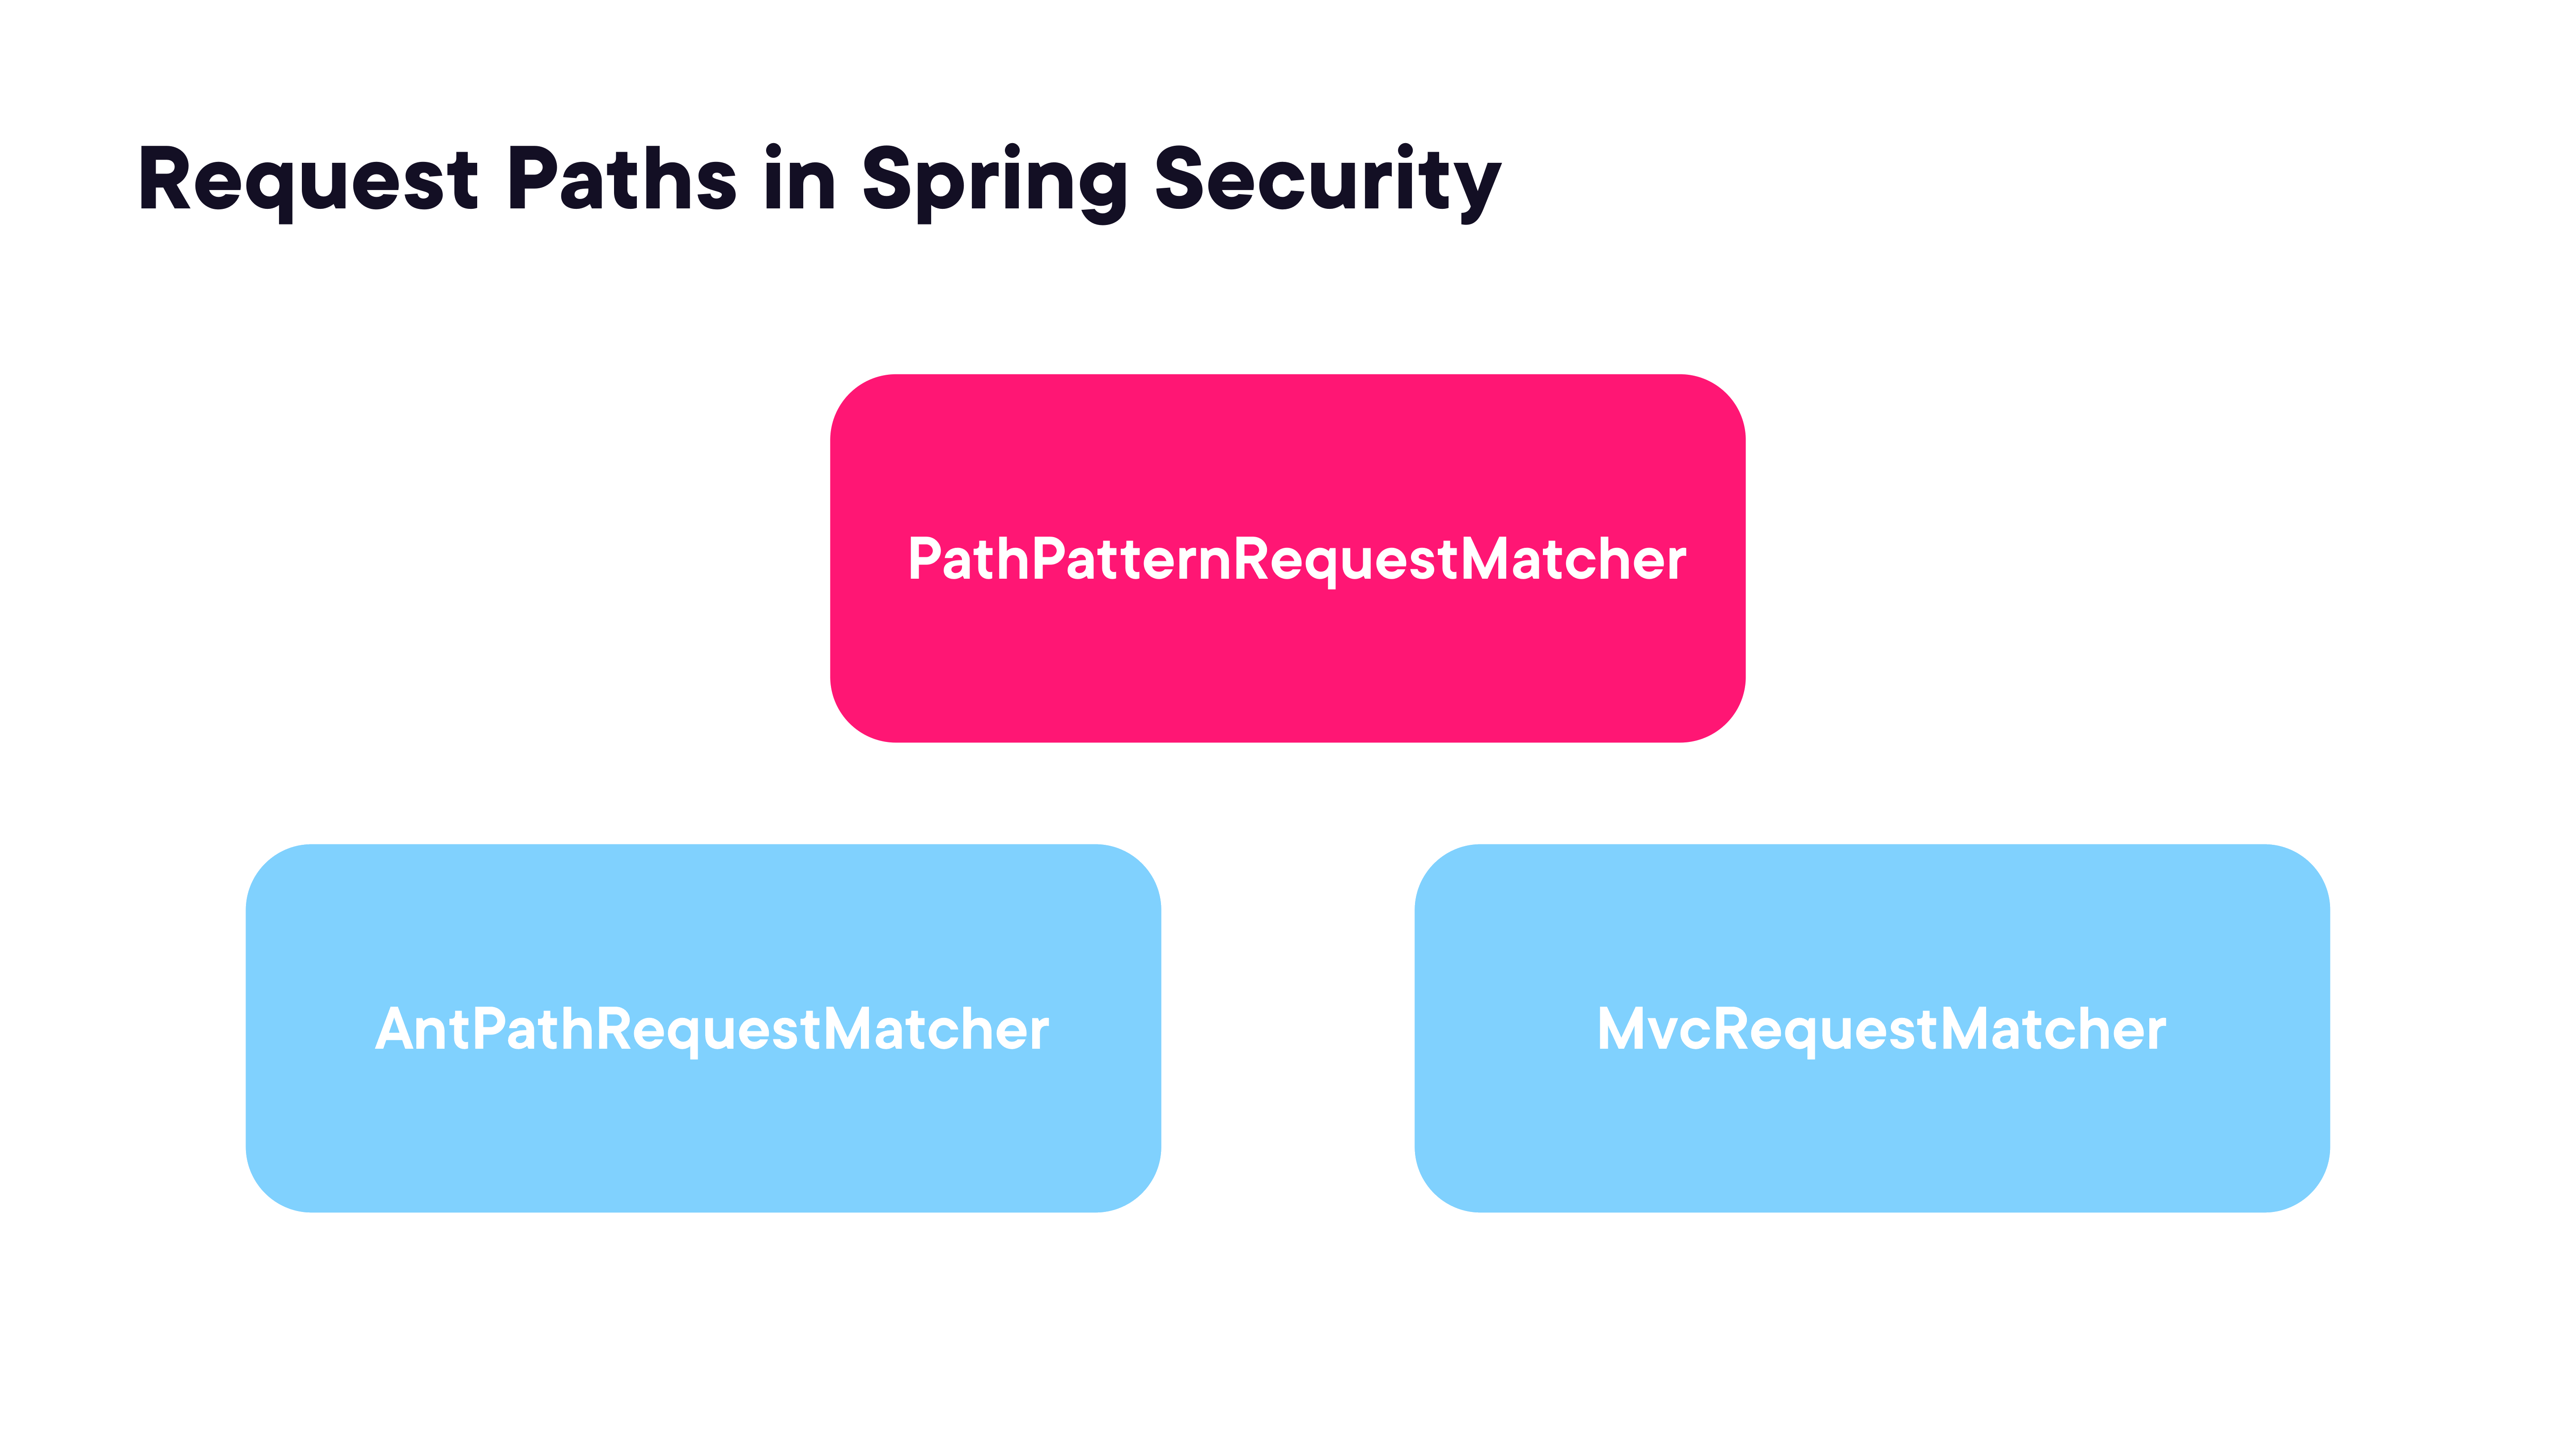

In [3]:
render_diagram(Path("assets/02-request-matcher-evolution.png"))

#### Before and After: Request Matchers

**Spring Security 6.x — choosing the right matcher was error-prone:**
```java
// AntPathRequestMatcher — Ant-style patterns, no MVC dispatcher integration
http.authorizeHttpRequests(auth -> auth
    .requestMatchers(new AntPathRequestMatcher("/api/**")).authenticated()
);

// MvcRequestMatcher — integrates with MVC dispatcher but required extra setup
http.authorizeHttpRequests(auth -> auth
    .requestMatchers(new MvcRequestMatcher(handlerMappingIntrospector, "/api/**")).authenticated()
);
// Confusion: which to use? MvcRequestMatcher was often required in Spring MVC apps
// but neither behaved identically in edge cases
```

**Spring Security 7 — one unified matcher:**
```java
// PathPatternRequestMatcher — a single choice, uses Spring's PathPattern engine
http.authorizeHttpRequests(auth -> auth
    .requestMatchers(PathPatternRequestMatcher.withDefaults().matcher("/api/**")).authenticated()
    .requestMatchers(PathPatternRequestMatcher.withDefaults().matcher(HttpMethod.GET, "/public/**")).permitAll()
    .anyRequest().denyAll()
);
```

Using `HttpSecurity.requestMatcher()` directly:
```java
// The shorter form — PathPatternRequestMatcher is now the implicit default
http.authorizeHttpRequests(auth -> auth
    .requestMatchers("/api/**").authenticated()
    .requestMatchers(HttpMethod.POST, "/api/admin/**").hasRole("ADMIN")
    .anyRequest().denyAll()
);
```

No configuration is required — Spring Security 7 automatically uses `PathPatternRequestMatcher` when `requestMatchers(String)` is called in a Spring MVC context.

### Simplified CSRF Configuration

Spring Security 7 adds `.csrf().spa()` — a one-method configuration shortcut for Single Page Applications that replaces the verbose double-cookie setup from Spring Security 6.

#### Before (Spring Security 6.x):

```java
@Bean
public SecurityFilterChain filterChain(HttpSecurity http) throws Exception {
    http
        .csrf(csrf -> csrf
            .csrfTokenRepository(CookieCsrfTokenRepository.withHttpOnlyFalse())
            .csrfTokenRequestHandler(new SpaCsrfTokenRequestHandler())
        );
    return http.build();
}

// Extra: required a custom component to handle the deferred token resolution for SPAs
@Component
final class SpaCsrfTokenRequestHandler extends CsrfTokenRequestAttributeHandler {
    private final CsrfTokenRequestHandler delegate = new XorCsrfTokenRequestAttributeHandler();

    @Override
    public void handle(HttpServletRequest request, HttpServletResponse response,
                       Supplier<CsrfToken> csrfToken) {
        this.delegate.handle(request, response, csrfToken);
    }

    @Override
    public String resolveCsrfTokenValue(HttpServletRequest request, CsrfToken csrfToken) {
        if (StringUtils.hasText(request.getHeader(csrfToken.getHeaderName()))) {
            return super.resolveCsrfTokenValue(request, csrfToken);
        }
        return this.delegate.resolveCsrfTokenValue(request, csrfToken);
    }
}
```

#### After (Spring Security 7):

```java
@Bean
public SecurityFilterChain filterChain(HttpSecurity http) throws Exception {
    http
        .csrf(csrf -> csrf.spa());  // Single method — all SPA CSRF handling configured
    return http.build();
}
```

`.spa()` sets up `CookieCsrfTokenRepository.withHttpOnlyFalse()` and the correct `CsrfTokenRequestAttributeHandler` behaviour automatically.

For traditional server-side rendered applications, default CSRF is unchanged — `.csrf(Customizer.withDefaults())` or no CSRF configuration at all.

### Testing Changes

Spring Boot 4 brings three important testing changes: `@MockitoBean` replaces `@MockBean`, `RestTestClient` replaces `MockMvc`/`WebTestClient` for servlet stack testing, and `@AutoConfigureMockMvc` is now required.

#### @MockBean → @MockitoBean

The Spring-proprietary `@MockBean` annotation is replaced by the standard Mockito annotation:

```java
// Spring Boot 3.x — Spring-proprietary annotation
import org.springframework.boot.test.mock.mockito.MockBean;
import org.springframework.boot.test.mock.mockito.SpyBean;

@SpringBootTest
class UserServiceTest {
    @MockBean
    private UserRepository userRepository;

    @SpyBean
    private UserService userService;
}
```

```java
// Spring Boot 4.x — standard Mockito annotations
import org.springframework.test.context.bean.override.mockito.MockitoBean;
import org.springframework.test.context.bean.override.mockito.MockitoSpyBean;

@SpringBootTest
class UserServiceTest {
    @MockitoBean
    private UserRepository userRepository;

    @MockitoSpyBean
    private UserService userService;
}
```

Same behaviour, different import. The annotation moves from Spring Boot to Spring Test proper.

#### @AutoConfigureMockMvc — Now Required Explicitly

In Spring Boot 3, adding `MockMvc` or `WebTestClient` as a field in a `@SpringBootTest` would auto-configure the infrastructure. In Spring Boot 4 you must explicitly add `@AutoConfigureMockMvc`:

```java
// Spring Boot 3.x — this just worked
@SpringBootTest
class ApiTest {
    @Autowired
    private MockMvc mockMvc;  // Auto-configured automatically
}

// Spring Boot 4.x — must be explicit
@SpringBootTest
@AutoConfigureMockMvc       // Required
class ApiTest {
    @Autowired
    private MockMvc mockMvc;
}
```

#### RestTestClient — Unified Test Client

`RestTestClient` is a new unified test client for the servlet stack. It combines the ergonomics of `WebTestClient` with full support for servlet-based tests — replacing the need to choose between `MockMvc` and `WebTestClient`.

**Before (Spring Boot 3.x) — two separate tools:**
```java
// MockMvc — for controller tests
@SpringBootTest
@AutoConfigureMockMvc
class OrderControllerTest {
    @Autowired
    private MockMvc mockMvc;

    @Test
    void shouldGetOrder() throws Exception {
        mockMvc.perform(get("/orders/1"))
            .andExpect(status().isOk())
            .andExpect(jsonPath("$.id").value(1))
            .andExpect(jsonPath("$.status").value("COMPLETED"));
    }
}

// WebTestClient — for reactive tests or when fluent API was preferred
@SpringBootTest(webEnvironment = SpringBootTest.WebEnvironment.RANDOM_PORT)
class OrderControllerReactiveTest {
    @Autowired
    private WebTestClient webTestClient;

    @Test
    void shouldGetOrder() {
        webTestClient.get().uri("/orders/1")
            .exchange()
            .expectStatus().isOk()
            .expectBody()
            .jsonPath("$.id").isEqualTo(1)
            .jsonPath("$.status").isEqualTo("COMPLETED");
    }
}
```

**After (Spring Boot 4.x) — RestTestClient for both:**
```java
import org.springframework.test.web.servlet.client.RestTestClient;

@SpringBootTest
@AutoConfigureMockMvc
class OrderControllerTest {
    @Autowired
    private RestTestClient restTestClient;

    @Test
    void shouldGetOrder() {
        restTestClient.get().uri("/orders/1")
            .exchange()
            .expectStatus().isOk()
            .expectBody()
            .jsonPath("$.id").isEqualTo(1)
            .jsonPath("$.status").isEqualTo("COMPLETED");
    }

    @Test
    void shouldCreateOrder() {
        Order newOrder = new Order("CUSTOMER-1", List.of(item1));

        restTestClient.post().uri("/orders")
            .contentType(MediaType.APPLICATION_JSON)
            .bodyValue(newOrder)
            .exchange()
            .expectStatus().isCreated()
            .expectHeader().exists("Location");
    }
}
```

`RestTestClient` uses the `MockMvc` infrastructure under the hood — no actual HTTP port is started — but exposes the same fluent API as `WebTestClient`.

### Migration Plan: Spring Boot 3 → Spring Boot 4

Migrating from Spring Boot 3 to Spring Boot 4 is best done in phases. Running the OpenRewrite migration recipe automates most of the mechanical changes.

#### OpenRewrite Automated Migration

Run the OpenRewrite Spring Boot 4 migration recipe first — it handles the majority of straightforward changes:

```bash
# Maven
mvn -U org.openrewrite.maven:rewrite-maven-plugin:run \
    -Drewrite.recipeArtifactCoordinates=org.openrewrite.recipe:rewrite-spring:LATEST \
    -Drewrite.activeRecipes=org.openrewrite.java.spring.boot4.UpgradeSpringBoot_4_0

# Gradle
./gradlew rewriteRun \
    -Drewrite.activeRecipes=org.openrewrite.java.spring.boot4.UpgradeSpringBoot_4_0
```

OpenRewrite handles: `javax` → `jakarta` imports, `@MockBean` → `@MockitoBean`, starter renames, basic security DSL updates, and JPA annotation migration.

#### Phase-by-Phase Migration Strategy

**Phase 1 — Upgrade to latest Spring Boot 3.x**
- Apply all available updates within the 3.x stream
- Fix any remaining deprecation warnings — they are removals in Spring Boot 4
- Run the Properties Migrator (`spring-boot-properties-migrator`) to identify configuration changes

**Phase 2 — Run OpenRewrite**
- Apply the automated migration recipe
- Review the diff carefully — automated migrations can miss edge cases
- Commit the automated changes as a separate commit for easy review

**Phase 3 — Dependencies**

| Check | Action |
|---|---|
| Undertow dependency | Remove — not supported; switch to Tomcat (default) or Jetty |
| `spring-boot-starter-web` | Rename to `spring-boot-starter-webmvc` |
| OAuth2 starters | Update names (see Module 01 table) |
| `webjars-locator-core` | Replace with `webjars-locator-lite` |
| Third-party dependencies | Check compatibility with Jakarta EE 11 and JDK 25 |
| Spring Boot Flyway/Liquibase | Add `spring-boot-starter-flyway` / `spring-boot-starter-liquibase` |

**Phase 4 — Properties**

| Old Key | New Key |
|---|---|
| `spring.data.mongodb.uri` | `spring.mongodb.uri` |
| `spring.jackson.*` | `spring.jackson.json.*` |
| `spring.session.redis.*` | `spring.session.data.redis.*` |
| Resource hint glob patterns | Drop leading `/`, change `.*\\.ext` to `**/*.ext` |

**Phase 5 — Code Changes**

| Change | Detail |
|---|---|
| `javax.*` → `jakarta.*` | All packages; OpenRewrite handles most |
| `@MockBean` → `@MockitoBean` | Import update only |
| `@SpyBean` → `@MockitoSpyBean` | Import update only |
| `.authorizeRequests()` | Replace with `.authorizeHttpRequests(auth -> ...)` |
| `.antMatchers()` | Replace with `.requestMatchers()` |
| `@Secured` / `@RolesAllowed` | Replace with `@PreAuthorize` |
| `@EnableGlobalMethodSecurity` | Replace with `@EnableMethodSecurity` |
| `@ConfigurationProperties` public fields | Add getters and setters |
| `@PersistenceContext EntityManager` | Replace with constructor injection |
| `hibernate5` package imports | Update to `jpa.hibernate` |

**Phase 6 — Tests**

| Change | Detail |
|---|---|
| `@AutoConfigureMockMvc` | Add explicitly to all `@SpringBootTest` that inject `MockMvc` |
| `MockMvc` / `WebTestClient` | Consider migrating to `RestTestClient` |
| `@AutoConfigureObservability` | Replace with `@AutoConfigureMetrics` + `@AutoConfigureTracing` |
| Hibernate query tests | Review for strict validation breakages |

**Phase 7 — Validation**

```bash
# Run full test suite
./mvnw verify

# Build and test native image (if applicable)
./mvnw -Pnative spring-boot:build-image
./mvnw -Pnative test
```

Checklist before promoting to production:
- [ ] All tests pass including integration tests
- [ ] Application starts without warning on property changes
- [ ] Native image builds and boots successfully
- [ ] Performance benchmarks show no regression
- [ ] Error responses checked — field names changed (`message` → `detail`)
- [ ] API client compatibility verified if Problem Details is enabled
- [ ] Security filter chain tested end-to-end
- [ ] Rollback plan documented: tag the last Spring Boot 3.x commit

#### Rollback Plan

Spring Boot 4 is not backwards-compatible with Spring Boot 3. Tag the last working Boot 3 commit before starting the migration:

```bash
git tag spring-boot-3-baseline
git push origin spring-boot-3-baseline
```

If you need to roll back, check out that tag and revert to the Spring Boot 3 dependency set.